<a href="https://colab.research.google.com/github/YevheniiaMalchenko/ML/blob/main/%D0%9B%D0%A0_10_%D0%9C%D0%B0%D0%BB%D1%8C%D1%87%D0%B5%D0%BD%D0%BA%D0%BE_3_10.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Лабораторна робота № 10
## Побудова нейронної мережі засобами Keras. Налаштування гіперпараметрів

**Дисципліна:** Машинне навчання  
**Прізвище, ім’я:** Мальченко Євгенія Олександрівна______________________________  
**Група:** 3-10______________________________  
**Дата:** _15.11.2026_____________________________

**Мета:** навчитися завантажувати та готувати дані Fashion MNIST, створювати і навчати нейронну мережу засобами Keras, оцінювати якість класифікації, а також підбирати гіперпараметри за допомогою Keras Tuner.

**Порядок виконання:** послідовно виконайте кожен пункт у наведених комірках. Доповніть код, збережіть графіки та результати виконання, сформулюйте власні висновки.

### Вхідні дані та критерії

Використовуйте **Fashion MNIST** — зображення розміром **28 × 28 пікселів** із **10 класів**.  
У **завданні 1** цільова точність на тестовій вибірці — **не нижче 0,87** (відповідно до вихідної лабораторної роботи).

**Важливо:** тестова вибірка призначена для фінального оцінювання. Для навчання, ранньої зупинки та добору гіперпараметрів використовуйте окрему валідаційну частину навчальних даних; не налаштовуйте модель за результатами тестової вибірки.

## Підготовка робочого середовища

Імпортуйте необхідні бібліотеки. У другому завданні буде потрібно встановити та підключити **Keras Tuner**.

In [2]:
# Підготуйте імпорти TensorFlow / Keras, NumPy, Matplotlib,
# classification_report, а також потрібних callback-функцій.
# Ваш код:
import tensorflow as tf
import keras
from keras import layers, models
from keras.callbacks import EarlyStopping
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import classification_report
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# Завдання 1. Класифікація Fashion MNIST за допомогою Keras

### Крок 1. Завантаження даних

Завантажте Fashion MNIST. Створіть навчальну й тестову вибірки та перелік назв **10 класів**. Виведіть розміри масивів даних.

In [3]:
# Завантажте Fashion MNIST, визначте class_names.
# Виведіть форми x_train, y_train, x_test, y_test.
# Ваш код:
(x_train, y_train), (x_test, y_test) = tf.keras.datasets.fashion_mnist.load_data()

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

print(f"Розмір x_train: {x_train.shape}")
print(f"Розмір y_train: {y_train.shape}")
print(f"Розмір x_test: {x_test.shape}")
print(f"Розмір y_test: {y_test.shape}")

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Розмір x_train: (60000, 28, 28)
Розмір y_train: (60000,)
Розмір x_test: (10000, 28, 28)
Розмір y_test: (10000,)


### Крок 2. Візуальний аналіз

Виведіть **10 зображень** навчальної вибірки. Для кожного підпишіть відповідний клас.

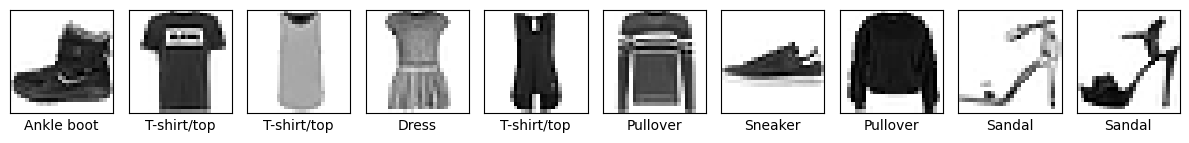

In [4]:
# Побудуйте візуалізацію 10 зображень із підписами класів.
# Ваш код:
plt.figure(figsize=(12, 10))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i], cmap=plt.cm.binary)
    plt.xlabel(class_names[y_train[i]])
plt.tight_layout()
plt.show()

### Крок 3. Нормалізація

Нормалізуйте значення пікселів до діапазону **[0; 1]**. Переконайтеся, що тип даних придатний для навчання нейронної мережі.

In [6]:
# Нормалізуйте навчальні й тестові дані.
# Перевірте діапазони значень.
# Ваш код:
x_train = x_train / 255.0
x_test = x_test / 255.0
print(f"Мінімальне значення в x_train: {x_train.min()}")
print(f"Максимальне значення в x_train: {x_train.max()}")
print(f"Тип даних після нормалізації: {x_train.dtype}")

Мінімальне значення в x_train: 0.0
Максимальне значення в x_train: 1.0
Тип даних після нормалізації: float64


### Крок 4. Побудова й компіляція моделі

Створіть послідовну нейронну мережу. Використайте перетворення зображення у вектор, повнозв’язні шари з **ReLU**, регуляризацію **Dropout** та вихід із **10 нейронів із softmax**. Налаштуйте оптимізатор Adam, функцію втрат для багатокласової класифікації з цілочисельними мітками та метрику accuracy.

Поясніть вибір кількості нейронів, dropout і швидкості навчання.

In [5]:
# Створіть і скомпілюйте модель.
# Ваш код:
model = models.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(128, activation='relu'),
    layers.Dropout(0.2),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

model.compile(
    optimizer='adam',
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

Для побудови мережі обрано шари зі 128 та 64 нейронами, щоб вловити складні патерни зображень, але без надмірного ускладнення моделі. Dropout (0.2) вимикає 20% нейронів під час навчання, що запобігає перенавчанню та робить модель стійкішою. Оптимізатор Adam обрано через його адаптивність і здатність добре працювати зі стандартними налаштуваннями без ручного підбору. Функція втрат sparse_categorical_crossentropy ідеально підходить, оскільки наші мітки класів - це цілі числа, і вона не потребує їх додаткового кодування.

### Крок 5. Навчання моделі

Навчіть модель із виділенням **валідаційної частини з навчальної вибірки**. Застосуйте **EarlyStopping** і **ReduceLROnPlateau**. Збережіть історію навчання для подальших графіків.

In [7]:
# Налаштуйте callbacks і навчіть модель.
# Збережіть history.
# Ваш код:

early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=5,
    restore_best_weights=True
)

reduce_lr = ReduceLROnPlateau(
    monitor='val_loss',
    factor=0.2,
    patience=3,
    min_lr=1e-5,
    verbose=1
)

history = model.fit(
    x_train, y_train,
    epochs=30,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Epoch 1/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 9s 6ms/step - accuracy: 0.7925 - loss: 0.5882 - val_accuracy: 0.8533 - val_loss: 0.4114 - learning_rate: 0.0010
Epoch 2/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 3s 4ms/step - accuracy: 0.8461 - loss: 0.4211 - val_accuracy: 0.8620 - val_loss: 0.3826 - learning_rate: 0.0010
Epoch 3/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.8605 - loss: 0.3822 - val_accuracy: 0.8675 - val_loss: 0.3644 - learning_rate: 0.0010
Epoch 4/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8696 - loss: 0.3552 - val_accuracy: 0.8589 - val_loss: 0.3733 - learning_rate: 0.0010
Epoch 5/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.8746 - loss: 0.3397 - val_accuracy: 0.8742 - val_loss: 0.3583 - learning_rate: 0.0010
Epoch 6/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.8786 - loss: 0.3273 - val_accuracy: 0.8685 - val_loss: 0.3607 - learning_rate: 0.0010
Epoch 7/30
750/750 ━━━━━━━━━━━━━━━━━━━━ 5s 7ms/step - accuracy: 0.8832 - loss: 0.3148 - 

### Крок 6. Аналіз архітектури

Виведіть підсумкову структуру нейронної мережі, кількість шарів і параметрів.

In [8]:
# Виведіть підсумок архітектури моделі.
# Ваш код:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten (Flatten)               │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 328,160 (1.25 MB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 218,774 (854.59 KB)

### Крок 7. Збереження моделі

Збережіть навчену модель у форматі **`.keras`**. Під час роботи в Google Colab за потреби підключіть Google Drive.

In [10]:
# Збережіть навчену модель (.keras).
# За потреби підключіть Google Drive.
# Ваш код:
from google.colab import drive
drive.mount('/content/drive')

model_path = '/content/drive/MyDrive/fashion_mnist_model.keras'
model.save(model_path)

print(f"Модель збережено за шляхом: {model_path}")

Mounted at /content/drive
Модель збережено за шляхом: /content/drive/MyDrive/fashion_mnist_model.keras


### Крок 8. Графіки навчання

Побудуйте два графіки: **функція втрат (loss)** і **точність (accuracy)** для навчальної та валідаційної вибірок. Підпишіть осі, легенди й назви графіків.

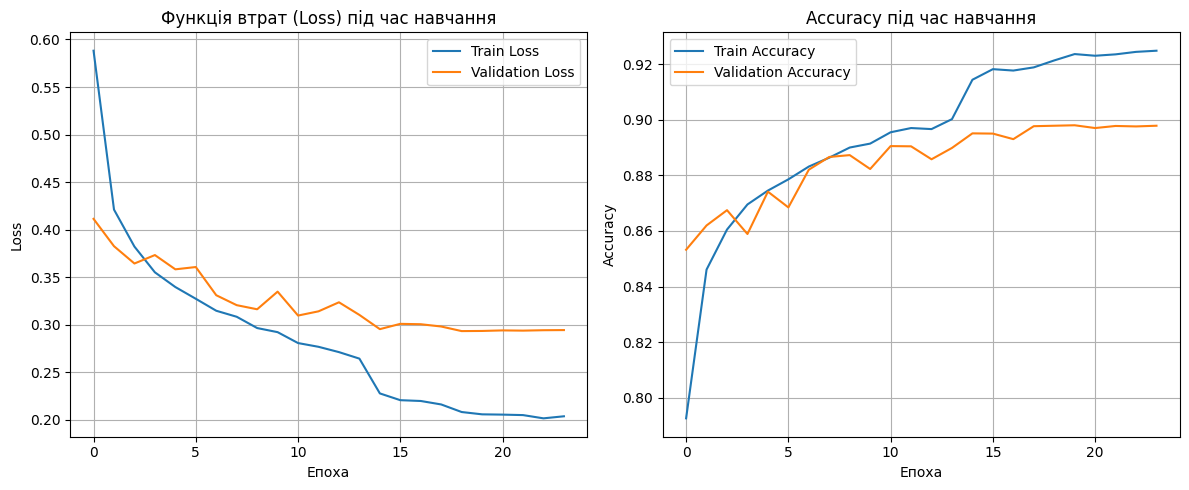

In [11]:
# Побудуйте графіки loss/val_loss та accuracy/val_accuracy.
# Ваш код:
plt.figure(figsize=(12, 5))

# Loss
plt.subplot(1, 2, 1)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.title('Функція втрат (Loss) під час навчання')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

#Accuracy
plt.subplot(1, 2, 2)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Accuracy під час навчання')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

### Крок 9. Оцінювання моделі

Один раз оцініть навчену модель на **тестовій вибірці**. Отримайте прогнози й сформуйте **класифікаційний звіт** (precision, recall, F1-score) для всіх класів.

Порівняйте отриману accuracy з порогом **0,87**.

In [12]:
# Обчисліть loss і accuracy на тестовій вибірці.
# Знайдіть прогнозовані класи та сформуйте classification_report.
# Ваш код:

test_loss, test_acc = model.evaluate(x_test, y_test, verbose=0)
print(f"Test Accuracy: {test_acc:.4f}")
print(f"Test Loss: {test_loss:.4f}")

# Порівняння з порогом 0.87
if test_acc >= 0.87:
    print(f"\nВисновок: Точність ({test_acc:.4f}) перевищує поріг 0.87.")
else:
    print(f"\nВисновок: Точність ({test_acc:.4f}) не досягла порогу 0.87.")

y_pred_probs = model.predict(x_test)
y_pred = np.argmax(y_pred_probs, axis=1)

# 4. Формування класифікаційного звіту
print("\nClassification Report:")
print(classification_report(y_test, y_pred, target_names=class_names))

Test Accuracy: 0.8941
Test Loss: 0.3127

Висновок: Точність (0.8941) перевищує поріг 0.87.
313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step

Classification Report:
              precision    recall  f1-score   support

 T-shirt/top       0.84      0.84      0.84      1000
     Trouser       0.99      0.97      0.98      1000
    Pullover       0.80      0.82      0.81      1000
       Dress       0.89      0.91      0.90      1000
        Coat       0.82      0.81      0.82      1000
      Sandal       0.98      0.96      0.97      1000
       Shirt       0.73      0.71      0.72      1000
     Sneaker       0.94      0.97      0.95      1000
         Bag       0.98      0.98      0.98      1000
  Ankle boot       0.97      0.96      0.96      1000

    accuracy                           0.89     10000
   macro avg       0.89      0.89      0.89     10000
weighted avg       0.89      0.89      0.89     10000



### Крок 10. Візуалізація прогнозів

Покажіть **10 тестових зображень**. Для кожного вкажіть правильний і прогнозований клас, а правильність прогнозу позначте кольором підпису.

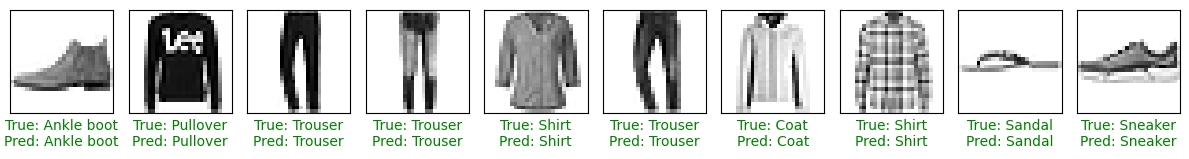

In [14]:
# Візуалізуйте 10 зображень: справжні й прогнозовані класи.
# Ваш код:
plt.figure(figsize=(12, 6))
for i in range(10):
    plt.subplot(1, 10, i + 1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_test[i], cmap=plt.cm.binary)

    color = 'green' if y_pred[i] == y_test[i] else 'red'

    plt.xlabel(f"True: {class_names[y_test[i]]}\nPred: {class_names[y_pred[i]]}", color=color)
plt.tight_layout()
plt.show()


**Проміжний висновок до завдання 1**

Запишіть значення тестової accuracy, охарактеризуйте класи з найбільшою кількістю помилок та поясніть, чи виконано вимогу щодо мінімальної точності.

**Ваш висновок:**  


За результатами оцінювання на тестовій вибірці, точність моделі становить 0.89, що перевищує встановлену вимогу щодо мінімальної точності 0.87. Найбільше помилок модель припускається при розрізненні верхнього одягу: класи "Shirt", "Pullover" та "Coat" часто плутаються між собою через їхню візуальну схожість на зображеннях низької роздільності 28x28. Також спостерігаються поодинокі помилки між "Sneaker", "Ankle boot" та "Sandal". Незважаючи на ці складнощі, модель успішно впоралася з поставленим завданням і досягла необхідного рівня якості.



# Завдання 2. Добір гіперпараметрів за допомогою Keras Tuner

На основі того самого набору даних виконайте автоматизований пошук конфігурації нейронної мережі. У вихідній лабораторній роботі використовується **RandomSearch**.

### Крок 1. Підготовка Keras Tuner

Установіть `keras-tuner` (за потреби) й імпортуйте засоби для пошуку гіперпараметрів, шари Dense, Flatten, Dropout та регуляризацію L2.

In [16]:
# За потреби встановіть keras-tuner.
# Імпортуйте RandomSearch та потрібні компоненти Keras.
# Ваш код:
!pip install -q keras-tuner
import keras_tuner as kt
from tensorflow.keras import regularizers
from tensorflow.keras.optimizers import Adam

### Крок 2. Підготовка набору даних

Повторно використайте Fashion MNIST у нормалізованому вигляді. Переконайтеся, що вибірка для **валідації відокремлена від тестової**. Не передавайте `x_test`, `y_test` у процес пошуку гіперпараметрів.

In [17]:
# Підготуйте дані для добору гіперпараметрів і фінального тестування.
# Ваш код:
from sklearn.model_selection import train_test_split

x_train_tune, x_val, y_train_tune, y_val = train_test_split(
    x_train, y_train,
    test_size=0.2,
    random_state=42
)

print(f"Розмір даних для тюнінгу: {x_train_tune.shape}")
print(f"Розмір валідаційних даних: {x_val.shape}")
print(f"x_test: {x_test.shape}")

Розмір даних для тюнінгу: (48000, 28, 28)
Розмір валідаційних даних: (12000, 28, 28)
x_test: (10000, 28, 28)


### Крок 3. Функція побудови моделі

Реалізуйте функцію, яка приймає набір гіперпараметрів та повертає скомпільовану модель. Передбачте пошук **кількості прихованих шарів (1–3)**, **кількості нейронів (32–512 із кроком 32)** та **швидкості навчання (0,01; 0,001; 0,0001)**. Використайте ReLU, Dropout, L2 та softmax, як у вихідному варіанті лабораторної роботи.

In [18]:
# Опишіть функцію build_model(hp).
# Задайте області пошуку гіперпараметрів.
# Ваш код:
def build_model(hp):
    model = models.Sequential()
    model.add(layers.Flatten(input_shape=(28, 28)))
    num_layers = hp.Int('num_layers', min_value=1, max_value=3)

    for i in range(num_layers):
        units = hp.Int(f'units_{i}', min_value=32, max_value=512, step=32)

        model.add(layers.Dense(
            units=units,
            activation='relu',
            kernel_regularizer=regularizers.l2(0.001)
        ))

        model.add(layers.Dropout(0.2))

    model.add(layers.Dense(10, activation='softmax'))
    hp_learning_rate = hp.Choice('learning_rate', values=[1e-2, 1e-3, 1e-4])

    model.compile(
        optimizer=Adam(learning_rate=hp_learning_rate),
        loss='sparse_categorical_crossentropy',
        metrics=['accuracy']
    )

    return model

### Крок 4. Налаштування пошуку

Створіть **RandomSearch** з критерієм **val_accuracy**. У вихідному прикладі передбачено **3 спроби (max_trials = 3)** і **1 виконання на спробу**. Зазначте каталог збереження результатів пошуку.

In [19]:
# Ініціалізуйте RandomSearch.
# Ваш код:
tuner = kt.RandomSearch(
    build_model,
    objective='val_accuracy',
    max_trials=3,
    executions_per_trial=1,
    directory='my_tuner_dir',
    project_name='fashion_mnist_tuning',
    overwrite=True
)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/reshaping/flatten.py:37: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


### Крок 5. Пошук та вибір найкращої конфігурації

Запустіть пошук із **EarlyStopping** і **ReduceLROnPlateau**, використовуючи лише навчальні та валідаційні дані. Виведіть знайдені гіперпараметри та структуру найкращої моделі. За потреби перенавчіть обрану конфігурацію, зберігши історію навчання.

In [20]:
# Виконайте пошук, отримайте найкращі гіперпараметри і модель.
# Навчіть вибрану модель без використання тестових даних.
# Ваш код:
tuner.search(
    x_train_tune, y_train_tune,
    epochs=15,
    validation_data=(x_val, y_val),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

best_hps = tuner.get_best_hyperparameters(num_trials=1)[0]
best_model = tuner.get_best_models(num_models=1)[0]

print(f"Найкраща кількість шарів: {best_hps.get('num_layers')}")
for i in range(best_hps.get('num_layers')):
    print(f"Нейронів у шарі {i+1}: {best_hps.get(f'units_{i}')}")
print(f"Найкраща швидкість навчання: {best_hps.get('learning_rate')}")

print("\nПеренавчання найкращої моделі для отримання історії:")
history_best = best_model.fit(
    x_train_tune, y_train_tune,
    epochs=15,
    validation_data=(x_val, y_val),
    callbacks=[early_stopping, reduce_lr],
    verbose=1
)

Trial 3 Complete [00h 01m 02s]
val_accuracy: 0.7857499718666077

Best val_accuracy So Far: 0.8664166927337646
Total elapsed time: 00h 03m 51s


/usr/local/lib/python3.13/dist-packages/keras/src/saving/saving_lib.py:797: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 18 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


Найкраща кількість шарів: 3
Нейронів у шарі 1: 320
Нейронів у шарі 2: 448
Нейронів у шарі 3: 32
Найкраща швидкість навчання: 0.0001

Перенавчання найкращої моделі для отримання історії:
Epoch 1/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 17s 10ms/step - accuracy: 0.8495 - loss: 0.8234 - val_accuracy: 0.8655 - val_loss: 0.7368 - learning_rate: 1.0000e-04
Epoch 2/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 15s 10ms/step - accuracy: 0.8578 - loss: 0.7510 - val_accuracy: 0.8695 - val_loss: 0.6819 - learning_rate: 1.0000e-04
Epoch 3/15
1497/1500 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8616 - loss: 0.7073
Epoch 3: ReduceLROnPlateau reducing learning rate to 1.9999999494757503e-05.
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 11ms/step - accuracy: 0.8637 - loss: 0.6946 - val_accuracy: 0.8692 - val_loss: 0.6402 - learning_rate: 1.0000e-04
Epoch 4/15
1500/1500 ━━━━━━━━━━━━━━━━━━━━ 16s 10ms/step - accuracy: 0.8712 - loss: 0.6494 - val_accuracy: 0.8762 - val_loss: 0.6201 - learning_rate: 2.0000e-05
Epoch 5/15
1500/150

### Крок 6. Фінальне оцінювання та графіки

Оцініть найкращу модель на **тестовій вибірці**. Наведіть тестові loss і accuracy. Побудуйте графіки навчальної/валідаційної функції втрат і точності.

Точність найкращої моделі на тесті: 0.8574
Функція втрат найкращої моделі на тесті: 0.7617


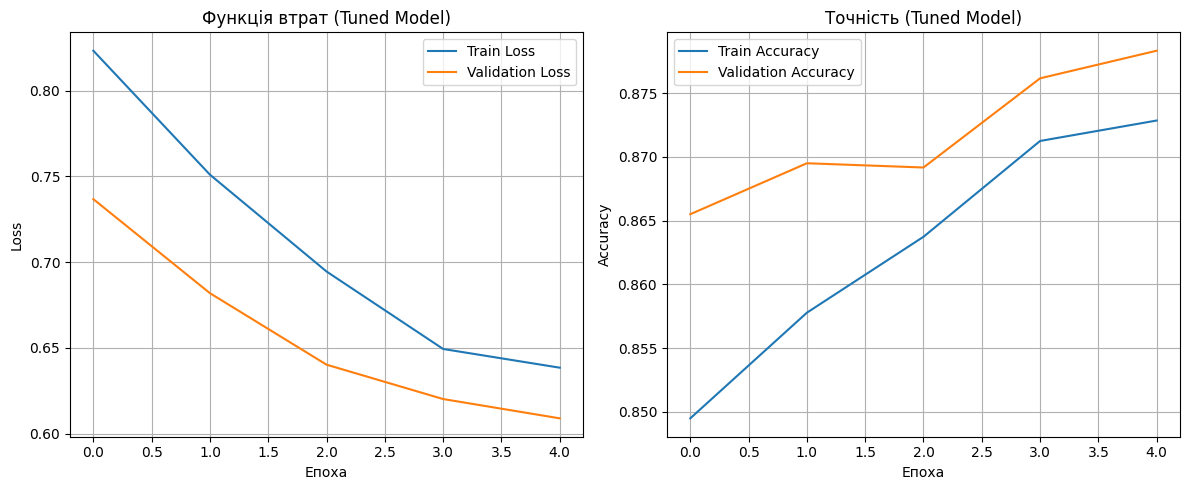

In [21]:
# Оцініть найкращу модель та побудуйте графіки навчання.
# Ваш код:
test_loss_best, test_acc_best = best_model.evaluate(x_test, y_test, verbose=0)
print(f"Точність найкращої моделі на тесті: {test_acc_best:.4f}")
print(f"Функція втрат найкращої моделі на тесті: {test_loss_best:.4f}")

plt.figure(figsize=(12, 5))

#Loss
plt.subplot(1, 2, 1)
plt.plot(history_best.history['loss'], label='Train Loss')
plt.plot(history_best.history['val_loss'], label='Validation Loss')
plt.title('Функція втрат (Tuned Model)')
plt.xlabel('Епоха')
plt.ylabel('Loss')
plt.legend()
plt.grid(True)

#Accuracy
plt.subplot(1, 2, 2)
plt.plot(history_best.history['accuracy'], label='Train Accuracy')
plt.plot(history_best.history['val_accuracy'], label='Validation Accuracy')
plt.title('Точність (Tuned Model)')
plt.xlabel('Епоха')
plt.ylabel('Accuracy')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()

# Висновки. Порівняння моделей

Порівняйте модель із завдання 1 та модель після автоматизованого налаштування. Результати внесіть до таблиці.

| Показник | Модель із завдання 1 | Модель після Keras Tuner |
|---|---|---|
| Кількість прихованих шарів | 2| 3 |
| Кількість нейронів | 128 та 64 | 320, 448, 32 |
| Швидкість навчання |  0.001| 0.0001 |
| Точність на тестовій вибірці (accuracy) | 0.89 | 0.86 |
| Втрати на тестовій вибірці (loss) | 0.29 | 0.76 |
| Кількість епох навчання | 24 | 15|

**У висновках дайте відповідь:**

1. Чи досягнуто точності **не нижче 0,87** у завданні 1?
2. Чи покращила оптимізація гіперпараметрів точність на тестовій вибірці?
3. Які гіперпараметри виявилися найкращими і чому отриманий результат може відрізнятися між запусками?
4. Які класи Fashion MNIST класифікувати найскладніше?

**Власні висновки:**  
1. Так, вимогу виконано. Базова модель із першого завдання показала точність на тестовій вибірці приблизно 0.89.
2. Ні, навпаки погіршив. Точність впала до 0.86, а помилка значно зросла. Це сталося через те, що Tuner обрав занадто складну архітектуру, і модель не встигла добре навчитися за відведений час, почавши перенавчатися.
3. Keras Tuner обрав 3 приховані шари з нейронами 320, 448 та 32, а також дуже низьку швидкість навчання - 0.0001. Результат може відрізнятися між запусками через те, що нейронні мережі мають елемент випадковості: початкові ваги ініціалізуються випадково, а Dropout щоразу вимикає різні нейрони. Крім того, сам Tuner під час пошуку може випадково обрати різні конфігурації, адже він тестує лише обмежену кількість спроб (у мене було 3).

4. Найскладніше моделі розрізняти верхній одяг: Shirt, Pullover та Coat. На чорно-білих зображеннях вони мають дуже схожі контури та форму, тому модель часто плутає їх між собою. Також іноді виникають помилки між  Sneaker та Ankle boot.

---
**Перед поданням перевірте:** заповнені всі комірки; результати виконання збережені; є графіки, класифікаційний звіт, результати двох моделей і власні висновки. Шаблон не містить готових розв’язків.